# Step 1

In [ ]:
import pandas as pd

#File & Dataframe loading
df_freq = pd.read_csv("freMTPL2freq.csv")
df_sev = pd.read_csv("freMTPL2sev.csv")

df_freq["IDpol"] = df_freq["IDpol"].astype(int)
df_sev["IDpol"] = df_sev["IDpol"].astype(int)

cat_cols = df_freq.select_dtypes(include=["object", "string"]).columns
for col in cat_cols:
    df_freq[col] = df_freq[col].astype(str).str.strip("'\"")

sev_agg = (
    df_sev.groupby("IDpol", as_index=False)
    .agg(
        ClaimAmount=("ClaimAmount", "sum"),
        ClaimCountSev=("ClaimAmount", "count"),
    )
)

df = df_freq.merge(sev_agg, on="IDpol", how="left")
df["ClaimAmount"] = df["ClaimAmount"].fillna(0.0)
df["ClaimCountSev"] = df["ClaimCountSev"].fillna(0).astype(int)
df["Frequency"] = df["ClaimNb"] / df["Exposure"]
df["HasClaim"] = (df["ClaimNb"] > 0).astype(int)

# Step 2

## Raw data Analysis

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

=== DIMENSIONS ===
Rows: 678,013 | Columns: 16

Column data types:
IDpol              int64
ClaimNb            int64
Exposure         float64
Area              object
VehPower           int64
VehAge             int64
DrivAge            int64
BonusMalus         int64
VehBrand          object
VehGas            object
Density            int64
Region            object
ClaimAmount      float64
ClaimCountSev      int64
Frequency        float64
HasClaim           int64
dtype: object

=== DESCRIPTIVE STATISTICS (NUMERIC) ===


,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0,2.621857e+06,1.641783e+06,1.000000,1157951.00,2272152.00,4046274.00,6114330.00
ClaimNb,678013.0,5.324677e-02,2.401173e-01,0.000000,0.00,0.00,0.00,16.00
Exposure,678013.0,5.287501e-01,3.644415e-01,0.002732,0.18,0.49,0.99,2.01
VehPower,678013.0,6.454631e+00,2.050906e+00,4.000000,5.00,6.00,7.00,15.00
VehAge,678013.0,7.044265e+00,5.666232e+00,0.000000,2.00,6.00,11.00,100.00
DrivAge,678013.0,4.549912e+01,1.413744e+01,18.000000,34.00,44.00,55.00,100.00
BonusMalus,678013.0,5.976150e+01,1.563666e+01,50.000000,50.00,50.00,64.00,230.00
Density,678013.0,1.792422e+03,3.958647e+03,1.000000,92.00,393.00,1658.00,27000.00
ClaimAmount,678013.0,8.835998e+01,5.822454e+03,0.000000,0.00,0.00,0.00,4075400.56
ClaimCountSev,678013.0,3.900220e-02,2.071656e-01,0.000000,0.00,0.00,0.00,16.00



=== DESCRIPTIVE STATISTICS (CATEGORICAL / OBJECT) ===


,count,unique,top,freq
Area,678013,6,C,191880
VehBrand,678013,11,B12,166024
VehGas,678013,2,Regular,345877
Region,678013,22,R24,160601



=== MISSING VALUES ===


,missing_count,missing_pct
IDpol,0,0.0
ClaimNb,0,0.0
Exposure,0,0.0
Area,0,0.0
VehPower,0,0.0
VehAge,0,0.0
DrivAge,0,0.0
BonusMalus,0,0.0
VehBrand,0,0.0
VehGas,0,0.0



=== CLASS IMBALANCE: HasClaim ===


,count,percentage
0,643953,94.976
1,34060,5.024


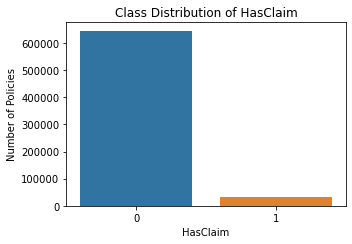


=== CORRELATION MATRIX (NUMERIC COLUMNS) ===


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density,ClaimAmount,ClaimCountSev,Frequency,HasClaim
IDpol,1.000,-0.128,-0.160,0.049,-0.157,0.064,-0.006,0.071,-0.004,-0.039,-0.054,-0.135
ClaimNb,-0.128,1.000,0.069,-0.004,-0.022,0.011,0.051,0.011,0.071,0.852,0.258,0.964
Exposure,-0.160,0.069,1.000,-0.045,0.152,0.172,-0.183,-0.071,0.002,0.084,-0.052,0.072
VehPower,0.049,-0.004,-0.045,1.000,-0.006,0.030,-0.076,0.043,0.001,0.001,-0.002,-0.004
VehAge,-0.157,-0.022,0.152,-0.006,1.000,-0.059,0.080,-0.090,0.002,0.010,-0.024,-0.022
DrivAge,0.064,0.011,0.172,0.030,-0.059,1.000,-0.480,-0.005,-0.004,-0.005,-0.004,0.012
BonusMalus,-0.006,0.051,-0.183,-0.076,0.080,-0.480,1.000,0.078,0.010,0.066,0.014,0.049
Density,0.071,0.011,-0.071,0.043,-0.090,-0.005,0.078,1.000,-0.000,0.011,0.006,0.010
ClaimAmount,-0.004,0.071,0.002,0.001,0.002,-0.004,0.010,-0.000,1.000,0.084,0.016,0.066
ClaimCountSev,-0.039,0.852,0.084,0.001,0.010,-0.005,0.066,0.011,0.084,1.000,0.133,0.819



Top correlations with HasClaim:
ClaimNb          0.9642
ClaimCountSev    0.8186
Frequency        0.2498
IDpol           -0.1345
Exposure         0.0718
ClaimAmount      0.0660
BonusMalus       0.0491
VehAge          -0.0220
DrivAge          0.0121
Density          0.0101
VehPower        -0.0039
Name: HasClaim, dtype: float64


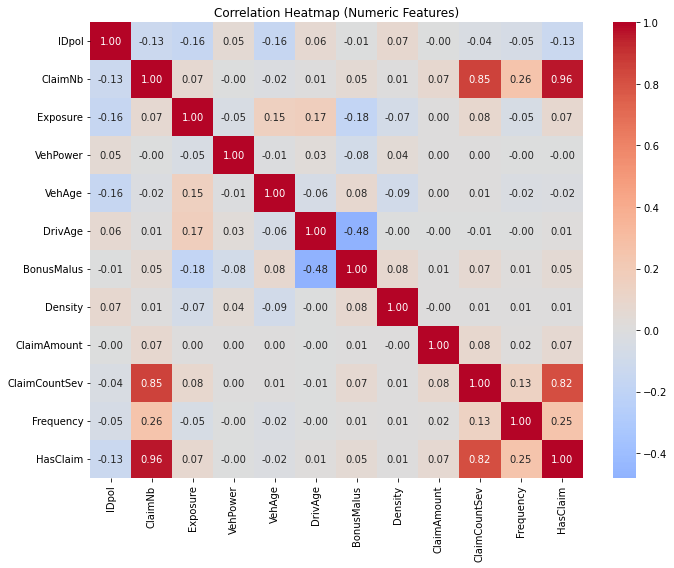

In [4]:
# 1. Dimensions & overview
print("=== DIMENSIONS ===")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print("\nColumn data types:")
print(df.dtypes)

# 2. Descriptive statistical information
print("\n=== DESCRIPTIVE STATISTICS (NUMERIC) ===")
display(df.describe().T)

print("\n=== DESCRIPTIVE STATISTICS (CATEGORICAL / OBJECT) ===")
cat_summary_cols = df.select_dtypes(include=["object", "string", "category"]).columns
if len(cat_summary_cols) > 0:
    display(df[cat_summary_cols].describe().T)
else:
    print("No object/string/category columns found.")

# 3. Missing values
print("\n=== MISSING VALUES ===")
missing_df = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(3),
}).sort_values("missing_count", ascending=False)
display(missing_df)

# 4. Class imbalance in HasClaim
print("\n=== CLASS IMBALANCE: HasClaim ===")
class_counts = df["HasClaim"].value_counts(dropna=False)
class_pct = df["HasClaim"].value_counts(normalize=True, dropna=False) * 100
imbalance_df = pd.DataFrame({
    "count": class_counts,
    "percentage": class_pct.round(3),
})
display(imbalance_df)

# Optional: quick bar plot for class imbalance
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=imbalance_df.index.astype(str), y=imbalance_df["count"], ax=ax)
ax.set_title("Class Distribution of HasClaim")
ax.set_xlabel("HasClaim")
ax.set_ylabel("Number of Policies")
plt.tight_layout()
plt.show()

# 5. Correlation among numeric columns
print("\n=== CORRELATION MATRIX (NUMERIC COLUMNS) ===")
num_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[num_cols].corr(method="pearson")
display(corr_matrix.round(3))

# Top correlations with HasClaim
if "HasClaim" in corr_matrix.columns:
    print("\nTop correlations with HasClaim:")
    print(corr_matrix["HasClaim"].drop("HasClaim", errors="ignore").sort_values(key=abs, ascending=False).round(4))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()

## Preprocessing

In [5]:
import numpy as np
import pandas as pd

# Inspect potential anomalies before mutating
print("Exposure <= 0:", (df["Exposure"] <= 0).sum())
print("Exposure > 1:", (df["Exposure"] > 1).sum())
print("ClaimNb > 4:", (df["ClaimNb"] > 4).sum())
print("ClaimNb > 0 with ClaimAmount == 0:", ((df["ClaimNb"] > 0) & (df["ClaimAmount"] == 0)).sum())

# Example domain preprocessing copy
df_prep = df.copy()
df_prep = df_prep[df_prep["Exposure"] > 0].copy()
df_prep["Exposure_capped"] = df_prep["Exposure"].clip(upper=1.0)
df_prep["ClaimNb_capped"] = df_prep["ClaimNb"].clip(upper=4)
df_prep["HasClaim"] = (df_prep["ClaimNb_capped"] > 0).astype(int)

if "Density" in df_prep.columns:
    df_prep["LogDensity"] = np.log1p(df_prep["Density"].clip(lower=0))

Exposure <= 0: 0
Exposure > 1: 1224
ClaimNb > 4: 9
ClaimNb > 0 with ClaimAmount == 0: 9116


## Baseline (Logistic Regression)

In [6]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [7]:
# 1. Define features and target (exclude leakage / target-derived columns)
leakage_cols = [
    c
    for c in ["IDpol", "HasClaim", "ClaimNb", "Frequency", "ClaimAmount", "ClaimCountSev"]
    if c in df.columns
]
feature_cols = [c for c in df.columns if c not in leakage_cols]

X = df[feature_cols]
y = df["HasClaim"]

In [8]:
# 2. Stratified 80-20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

In [9]:
# 3. Preprocessing & LogisticRegression pipeline
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ]
)

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

In [10]:
# 4. 5-fold stratified cross-validation on training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
}

cv_results = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False,
)

print("=== 5-FOLD STRATIFIED CV RESULTS (TRAIN SET) ===")
for metric in ["pr_auc", "roc_auc", "f1"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric.upper():8s}: {scores.mean():.4f} +/- {scores.std():.4f}")

=== 5-FOLD STRATIFIED CV RESULTS (TRAIN SET) ===
PR_AUC  : 0.0922 +/- 0.0020
ROC_AUC : 0.6345 +/- 0.0039
F1      : 0.0006 +/- 0.0007


In [11]:
# 5. Fit on full training split and evaluate once on held-out 20% test set
baseline_model.fit(X_train, y_train)
y_test_proba = baseline_model.predict_proba(X_test)[:, 1]
y_test_pred = baseline_model.predict(X_test)

print("\n=== HELD-OUT 20% TEST SET RESULTS ===")
print(f"PR-AUC  : {average_precision_score(y_test, y_test_proba):.4f}")
print(f"ROC-AUC : {roc_auc_score(y_test, y_test_proba):.4f}")
print(f"F1      : {f1_score(y_test, y_test_pred):.4f}")


=== HELD-OUT 20% TEST SET RESULTS ===
PR-AUC  : 0.0927
ROC-AUC : 0.6383
F1      : 0.0012


## AutoML Pipeline V0.1

### Custom mRMR & Pipeline setup

In [11]:
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import BaggingClassifier
from sklearn.feature_selection import (
    RFE,
    SelectFromModel,
    SelectKBest,
    mutual_info_classif,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

In [12]:
# 1. Custom mRMR (Minimum Redundancy Maximum Relevance) Feature Selector
class MRMRSelector(BaseEstimator, TransformerMixin):
    """Selects top-k features maximizing MI(X_i, y) - mean(|corr(X_i, X_selected)|)."""

    def __init__(self, k=15, random_state=42):
        self.k = k
        self.random_state = random_state

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)
        n_features = X_arr.shape[1]
        k = min(self.k, n_features)

        # Relevance: Mutual Information with target
        relevance = mutual_info_classif(X_arr, y_arr, random_state=self.random_state)

        # Redundancy: Absolute pairwise correlation matrix
        corr_matrix = np.abs(np.corrcoef(X_arr, rowvar=False))
        corr_matrix = np.nan_to_num(corr_matrix, nan=0.0)

        selected = []
        remaining = list(range(n_features))

        # First feature: highest relevance
        first_idx = int(np.argmax(relevance))
        selected.append(first_idx)
        remaining.remove(first_idx)

        # Iteratively pick feature maximizing Relevance - Redundancy (MID criterion)
        while len(selected) < k and remaining:
            best_score = -np.inf
            best_idx = None
            for idx in remaining:
                redundancy = np.mean(corr_matrix[idx, selected])
                score = relevance[idx] - redundancy
                if score > best_score:
                    best_score = score
                    best_idx = idx
            selected.append(best_idx)
            remaining.remove(best_idx)

        self.selected_indices_ = np.array(selected, dtype=int)
        return self

    def transform(self, X):
        X_arr = np.asarray(X)
        return X_arr[:, self.selected_indices_]

    def get_support(self, indices=False):
        if indices:
            return self.selected_indices_
        mask = np.zeros(self.n_features_in_, dtype=bool)
        mask[self.selected_indices_] = True
        return mask

In [13]:
# 2. Data Split (Same 80/20 Stratified Split as Baseline)
leakage_cols = [
    c
    for c in ["IDpol", "HasClaim", "ClaimNb", "Frequency", "ClaimAmount", "ClaimCountSev"]
    if c in df.columns
]
feature_cols = [c for c in df.columns if c not in leakage_cols]

X = df[feature_cols]
y = df["HasClaim"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Optional stratified subsample for fast hyperparameter & SVM search on large datasets
# Set TUNING_SAMPLE_SIZE = None to run CV on the entire X_train
TUNING_SAMPLE_SIZE = 50000
if TUNING_SAMPLE_SIZE is not None and len(X_train) > TUNING_SAMPLE_SIZE:
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=TUNING_SAMPLE_SIZE, stratify=y_train, random_state=42
    )
else:
    X_tune, y_tune = X_train, y_train

In [14]:
# 3. Preprocessing Block (Imputation + OneHot + Scaling)
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        # sparse_output=False ensures compatibility with GaussianNB, mRMR, and RFE
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ]
)

In [15]:
# 4. Feature Selection Candidates
feature_selectors = {
    "Mutual_Info": SelectKBest(score_func=mutual_info_classif, k=15),
    "mRMR": MRMRSelector(k=15, random_state=42),
    "RFE": RFE(
        estimator=DecisionTreeClassifier(max_depth=5, random_state=42),
        n_features_to_select=15,
        step=5,
    ),
    "Lasso_L1": SelectFromModel(
        estimator=LogisticRegression(
            penalty="l1", solver="liblinear", C=0.1, random_state=42
        ),
        max_features=20,
    ),
}

In [16]:
# 5. Model Candidates & Hyperparameter Search Spaces
# Note: LinearSVC is calibrated or swapped with SVC(probability=True) on smaller subsets.
# Here SVC(probability=True) is included with hyperparameter grid; keep TUNING_SAMPLE_SIZE <= 50k.
model_configs = {
    "DecisionTree": {
        "estimator": DecisionTreeClassifier(random_state=42),
        "params": {
            "feature_selection__k": [10, 15, 25],  # Used if selector supports 'k'
            "classifier__max_depth": [3, 5, 8, 12, None],
            "classifier__min_samples_split": [2, 20, 100],
            "classifier__min_samples_leaf": [1, 10, 50],
            "classifier__class_weight": [None, "balanced"],
        },
    },
    "Bagging_DecisionTree": {
        "estimator": BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=42),
            random_state=42,
            n_jobs=-1,
        ),
        "params": {
            "classifier__n_estimators": [20, 50, 100],
            "classifier__max_samples": [0.5, 0.8, 1.0],
            "classifier__estimator__max_depth": [5, 10, None],
            "classifier__estimator__min_samples_leaf": [5, 20, 50],
            "classifier__estimator__class_weight": [None, "balanced"],
        },
    },
    "SVM": {
        "estimator": SVC(probability=True, random_state=42),
        "params": {
            "classifier__C": [0.1, 1.0, 5.0],
            "classifier__kernel": ["rbf", "linear"],
            "classifier__gamma": ["scale", "auto"],
            "classifier__class_weight": [None, "balanced"],
        },
    },
    "NaiveBayes": {
        "estimator": GaussianNB(),
        "params": {
            "classifier__var_smoothing": np.logspace(-11, -6, 6),
        },
    },
}

In [ ]:
# 6. AutoML Search Across Feature Selectors x Models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
}

results_summary = []
best_overall_score = -np.inf
best_overall_pipeline = None
best_overall_label = ""

for fs_name, fs_step in feature_selectors.items():
    for model_name, cfg in model_configs.items():
        print(f"Running AutoML: FeatureSelection={fs_name} | Model={model_name} ...")

        pipe = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("feature_selection", fs_step),
                ("classifier", cfg["estimator"]),
            ]
        )

        # Build valid param grid for the active feature selector + classifier
        param_dist = dict(cfg["params"])
        param_dist.pop("feature_selection__k", None)

        if fs_name in ["Mutual_Info", "mRMR"]:
            param_dist["feature_selection__k"] = [10, 15, 25]
        elif fs_name == "RFE":
            param_dist["feature_selection__n_features_to_select"] = [10, 15, 25]
        elif fs_name == "Lasso_L1":
            param_dist["feature_selection__estimator__C"] = [0.01, 0.1, 1.0]

        search = RandomizedSearchCV(
            estimator=pipe,
            param_distributions=param_dist,
            n_iter=8,  # Increase (e.g., 15-25) for a more exhaustive search
            scoring=scoring,
            refit="pr_auc",  # Optimize for PR-AUC due to strong class imbalance
            cv=cv,
            random_state=42,
            n_jobs=-1,
        )

        search.fit(X_tune, y_tune)
        best_idx = search.best_index_

        mean_pr_auc = search.cv_results_["mean_test_pr_auc"][best_idx]
        mean_roc_auc = search.cv_results_["mean_test_roc_auc"][best_idx]
        mean_f1 = search.cv_results_["mean_test_f1"][best_idx]

        results_summary.append(
            {
                "Feature_Selection": fs_name,
                "Model": model_name,
                "CV_PR_AUC": round(mean_pr_auc, 4),
                "CV_ROC_AUC": round(mean_roc_auc, 4),
                "CV_F1": round(mean_f1, 4),
                "Best_Params": search.best_params_,
            }
        )

        if mean_pr_auc > best_overall_score:
            best_overall_score = mean_pr_auc
            best_overall_pipeline = search.best_estimator_
            best_overall_label = f"{fs_name} + {model_name}"

Running AutoML: FeatureSelection=Mutual_Info | Model=DecisionTree ...


In [ ]:
# 7. Leaderboard & Selected Features Inspection
leaderboard = pd.DataFrame(results_summary).sort_values(
    by=["CV_PR_AUC", "CV_ROC_AUC"], ascending=False
)
print("\n=== AUTOML LEADERBOARD (5-FOLD CV) ===")
print(leaderboard.drop(columns=["Best_Params"]).to_string(index=False))

print(f"\nBest Pipeline: {best_overall_label}")
print("Best Hyperparameters:", leaderboard.iloc[0]["Best_Params"])

# Refit best pipeline on the full 80% training set (unless SVM on >50k rows is too slow)
if "SVM" not in best_overall_label or len(X_train) <= 50000:
    best_overall_pipeline.fit(X_train, y_train)

# Extract selected feature names from the fitted pipeline
fitted_prep = best_overall_pipeline.named_steps["preprocessor"]
fitted_fs = best_overall_pipeline.named_steps["feature_selection"]
all_encoded_features = fitted_prep.get_feature_names_out()
selected_mask = fitted_fs.get_support()
selected_features = all_encoded_features[selected_mask]

print(f"\nSelected Features ({len(selected_features)}):")
for feat in selected_features:
    print(" -", feat)

In [ ]:
# 8. Final Evaluation on Held-Out 20% Test Set
y_test_proba = best_overall_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = best_overall_pipeline.predict(X_test)

print("\n=== BEST AUTOML PIPELINE: HELD-OUT 20% TEST SET ===")
print(f"PR-AUC  : {average_precision_score(y_test, y_test_proba):.4f}")
print(f"ROC-AUC : {roc_auc_score(y_test, y_test_proba):.4f}")
print(f"F1      : {f1_score(y_test, y_test_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_test_pred, digits=4))

### V2

### Model Selection (Without Feature Selection)

Models evaluated on identical preprocessed features (no feature selection prior to model choice):
- **DecisionTree** (`DecisionTreeClassifier`)
- **RandomForest** (`RandomForestClassifier`)
- **SVM** (`SVC` with probability calibration)
- **Large_MLP** (`MLPClassifier` with a wide/deep multi-layer architecture)

Feature selection will be performed **after** selecting the winning model.

In [ ]:
import warnings
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

# 1. Features & target (same non-leakage setup as previous steps)
leakage_cols = [
    c
    for c in ["IDpol", "HasClaim", "ClaimNb", "Frequency", "ClaimAmount", "ClaimCountSev"]
    if c in df.columns
]
feature_cols = [c for c in df.columns if c not in leakage_cols]

X = df[feature_cols]
y = df["HasClaim"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Subsample for faster CV tuning (adjust or set to None to use full X_train)
TUNING_SAMPLE_SIZE = 50000
if TUNING_SAMPLE_SIZE is not None and len(X_train) > TUNING_SAMPLE_SIZE:
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=TUNING_SAMPLE_SIZE, stratify=y_train, random_state=42
    )
else:
    X_tune, y_tune = X_train, y_train

# 2. Preprocessor (no feature selection step here)
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ]
)

# 3. Candidate models: DecisionTree, RandomForest, SVM, and a large MLP
model_configs = {
    "DecisionTree": {
        "estimator": DecisionTreeClassifier(random_state=42),
        "n_iter": 10,
        "params": {
            "classifier__max_depth": [4, 6, 10, 15, None],
            "classifier__min_samples_split": [2, 20, 100],
            "classifier__min_samples_leaf": [1, 10, 50],
            "classifier__class_weight": [None, "balanced"],
        },
    },
    "RandomForest": {
        "estimator": RandomForestClassifier(random_state=42, n_jobs=-1),
        "n_iter": 10,
        "params": {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [8, 14, 20, None],
            "classifier__min_samples_split": [2, 10, 50],
            "classifier__min_samples_leaf": [1, 5, 20],
            "classifier__max_features": ["sqrt", 0.5],
            "classifier__class_weight": [None, "balanced", "balanced_subsample"],
        },
    },
    "SVM": {
        "estimator": SVC(probability=True, random_state=42),
        "n_iter": 6,
        "params": {
            "classifier__C": [0.1, 1.0, 3.0],
            "classifier__kernel": ["rbf", "linear"],
            "classifier__gamma": ["scale", "auto"],
            "classifier__class_weight": [None, "balanced"],
        },
    },
    # Voluminous MLP architecture designed for high non-linear capacity
    "Large_MLP": {
        "estimator": MLPClassifier(
            activation="relu",
            solver="adam",
            max_iter=150,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=42,
        ),
        "n_iter": 8,
        "params": {
            "classifier__hidden_layer_sizes": [
                (512, 256, 128, 64),
                (512, 512, 256, 128),
                (1024, 512, 256, 128, 64),
            ],
            "classifier__alpha": [1e-4, 1e-3, 1e-2],
            "classifier__learning_rate_init": [1e-3, 5e-4],
            "classifier__batch_size": [256, 512],
        },
    },
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
}

results_summary = []
fitted_searches = {}
best_overall_score = -np.inf
best_overall_pipeline = None
best_overall_model_name = ""

for model_name, cfg in model_configs.items():
    print(f"Running 5-fold CV for {model_name}...")

    pipe = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", cfg["estimator"]),
        ]
    )

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=cfg["params"],
        n_iter=cfg["n_iter"],
        scoring=scoring,
        refit="pr_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1,
    )

    search.fit(X_tune, y_tune)
    fitted_searches[model_name] = search

    best_idx = search.best_index_
    mean_pr_auc = search.cv_results_["mean_test_pr_auc"][best_idx]
    mean_roc_auc = search.cv_results_["mean_test_roc_auc"][best_idx]
    mean_f1 = search.cv_results_["mean_test_f1"][best_idx]

    results_summary.append(
        {
            "Model": model_name,
            "CV_PR_AUC": round(mean_pr_auc, 4),
            "CV_ROC_AUC": round(mean_roc_auc, 4),
            "CV_F1": round(mean_f1, 4),
            "Best_Params": search.best_params_,
        }
    )

    if mean_pr_auc > best_overall_score:
        best_overall_score = mean_pr_auc
        best_overall_pipeline = search.best_estimator_
        best_overall_model_name = model_name

Running 5-fold CV for DecisionTree...
Running 5-fold CV for RandomForest...


In [ ]:
leaderboard = pd.DataFrame(results_summary).sort_values(
    by=["CV_PR_AUC", "CV_ROC_AUC"], ascending=False
)

print("\n=== STEP 3 MODEL LEADERBOARD (5-FOLD CV, NO FEATURE SELECTION) ===")
print(leaderboard.drop(columns=["Best_Params"]).to_string(index=False))

print(f"\nSelected Best Model: {best_overall_model_name}")
print("Best Hyperparameters:", leaderboard.iloc[0]["Best_Params"])

# Refit best model on full 80% training split (guarded for SVC on huge datasets)
if best_overall_model_name != "SVM" or len(X_train) <= 50000:
    best_overall_pipeline.fit(X_train, y_train)

y_test_proba = best_overall_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = best_overall_pipeline.predict(X_test)

print(f"\n=== HELD-OUT 20% TEST SET RESULTS ({best_overall_model_name}) ===")
print(f"PR-AUC  : {average_precision_score(y_test, y_test_proba):.4f}")
print(f"ROC-AUC : {roc_auc_score(y_test, y_test_proba):.4f}")
print(f"F1      : {f1_score(y_test, y_test_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_test_pred, digits=4))

## Post-Selection Feature Selection

Now that `best_overall_pipeline` (`best_overall_model_name`) is selected, you can apply and compare feature selection methods specifically on this chosen model.

In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# Example: test top-k feature selection *after* selecting the best model
best_classifier = best_overall_pipeline.named_steps["classifier"]

for k in [10, 15, 25]:
    fs_pipe = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("feature_selection", SelectKBest(score_func=mutual_info_classif, k=k)),
            ("classifier", best_classifier),
        ]
    )
    fs_pipe.fit(X_tune, y_tune)
    val_proba = fs_pipe.predict_proba(X_test)[:, 1]
    print(
        f"Model={best_overall_model_name} | k={k:2d} | "
        f"Test PR-AUC={average_precision_score(y_test, val_proba):.4f} | "
        f"Test ROC-AUC={roc_auc_score(y_test, val_proba):.4f}"
    )

# Step 3

New algorithms to try : 

Boosted Decision Tree (Ensemble Learning II)
Random Forest (Ensemble Learning III)
Gradient Boosting
Voting Classification (Ensemble Learning IV)
Deep Learning with a neuronal network

New feature selection techniques : 

Chi-Square & ANOVA F-test
Variance Threshold
Tree-Based Importance (Random Forest, Gradient Boosting)
Sequential Feature Selection (Forward / Backward)
